# Phase 4g: Results pack

**Date:** 2026-11-04. Built by `code/python/04g_results_pack.py`. Nothing here estimates a new model. All results are associations.

**Which AI measure:** where both appear, data-center jobs (BLS, one consistent series) are the more reliable extension measure.

In [1]:
import pandas as pd
from IPython.display import display, Image, Markdown
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 30); pd.set_option('display.max_colwidth', 70); pd.set_option('display.max_rows', 80)
P = '../results/2026-11-04/paper/'
display(Markdown(open(P + 'findings.md').read()))

# Findings

All results are associations. Generated by `code/python/04g_results_pack.py`; every number is logged in `number_check.csv`.

## H1: AI and consumption, efficiency and renewable share

**What we tested:** private data-center jobs per 1,000 workers, lagged one year, with state and year fixed effects, four controls and SEs clustered by state, on 50 states in 2015-2025 (N = 550).

**The numbers:** the coefficient is -0.0016 for consumption (p = 0.795), 0.0022 for efficiency (p = 0.707) and -0.0101 for renewable share (p = 0.100). The new-capacity result is positive in raw MW, 70.8 MW (p = 0.033), driven by large-grid states: per 1,000 MW of 2015 capacity it's 1.00 (p = 0.616). No AI-squared curve passes the Lind-Mehlum test.

**Supported?** No. The core outcomes aren't significant under clustered SEs.

**Main caveats:** the timing test fails. For renew_share, next year's AI predicts this year's share (-0.0197, p = 0.006), and with both in one model the lead keeps the association (-0.0210, p = 0.007) while the lag is about zero (0.0015, p = 0.827). The negative association reflects where and when data-center jobs grow (reverse timing or selection), not AI lowering the renewable share. new_renew_mw gets the same caution: its lead is also positive (86.8, p = 0.028), and with both in one model neither is significant. The RPS control, using the LBNL current RPS/CES schedule, and all-ownership AI change no result. A shift-share instrument is too weak to settle the timing question (KP F = 2.81), so we treat the IV as uninformative.

**Weather check:** with NOAA heating and cooling degree days as controls on the 48 contiguous states, the consumption coefficient is -0.0021 (p = 0.711), against -0.0009 (p = 0.880) on the same states without them. Degree days are significant (p < 0.001 for HDD, p < 0.001 for CDD) and within R2 rises from 0.22 to 0.33, so weather accounts for part of consumption without changing the AI coefficient.

**What we can rule out:** per one within-state SD of AI (0.5212, the SD of winsorized lagged AI after removing state and year effects), the 95% CI is -0.71 to 0.54 percent for consumption, -0.50 to 0.73 percent for efficiency and -1.16 to 0.11 percentage points for renewable share.

## H2: mediation

**What we tested:** whether AI is associated with outcomes through the tech-job share (H2a; HMA as the memo version) or economic density (H2b), with Sobel tests and a cluster bootstrap.

**The numbers:** AI isn't associated with the tech share (-0.000157, p = 0.454). Across all 9 mediator-outcome pairs, Sobel p-values run from 0.322 to 0.991, and every bootstrap CI includes zero.

**Supported?** No channel is supported.

**Main caveat:** HMA's first stage is positive by construction, since it's built from AI. Economic density is nearly redundant with GDP under state fixed effects. Share mediated isn't reported.

## H3: spillovers

**What we tested:** spatial Durbin models with inverse-distance weights (main) and border weights (check), direct, indirect and total effects, and a timing test using neighbors' next-year AI.

**The numbers:** On 2015-2023, the only years the timing test can run, the renew_share spillover isn't significant, and with border weights neighbors' future AI carries the association rather than their past AI. The full-sample estimate (-0.161, p = 0.035) can't be separated from this reverse timing. H3 is not supported.

**Main caveat:** on the main inverse-distance weights, the timing test can't tell lag from lead: both CIs are wide. The border-weights result is -0.0406 for the lead (p = 0.027) and 0.0098 for the lag (p = 0.583) in the clustered SLX. Residual spatial dependence after two-way FE also means clustered SEs may be too small.

**Exploratory note:** with lead and lag in one model, the SLX shows neighbors' past AI as significant for ln_ec (0.0419, p = 0.034, inverse distance; 0.0234, p = 0.024, border) and for border-weights ln_ee (-0.0209, p = 0.033). The SDM doesn't confirm it: the indirect CIs for those rows include zero. With this many tests, a few p < 0.05 are expected by chance. We treat this as exploratory, not as a spillover finding.

## The Fang test

**What we tested:** Fang, Lee & Li (2025): log renewable consumption on log AI job postings, EPU and controls, state FE only, 2018-2021 with DC. Then a one-step-at-a-time bridge to our design, with postings and data-center jobs side by side. **Data-center jobs (BLS, one consistent series) are the more reliable extension measure:** almost every postings year comes from a different report edition, so postings mix real change with method changes.

**The numbers:** Fang's AI coefficient (0.0531) doesn't reproduce on current data: -0.0188 (p = 0.317). EIA changed how SEDS counts wind, solar, hydro and geothermal in October 2023, starting with the 2022 data cycle and applied to all years, from fossil fuel equivalency to captured energy at 3,412 Btu/kWh ([EIA notice](https://www.eia.gov/state/seds/seds-change/index.php)). On an approximate rebuild of the old basis, the sign comes back: 0.0342 in column 2 (p = 0.025) and 0.0216 in column 6 (p = 0.287). With the lag, year effects, clustering and the longer sample, neither measure is significant: postings -0.0479 (p = 0.109) and data-center jobs -0.0567 (p = 0.208). AI x state EPU is positive in Fang's spec (0.0193, p = 0.002) and not significant under two-way FE (p = 0.163).

**Supported?** Fang's positive association isn't supported in our design. The by-type pattern is partly similar: solar positive and biomass negative in Fang's spec with postings.

**Net-producer split:** Fang's rule is electricity production above consumption from EIA, with the series not stated (PDF p. 4), giving 76 net-producer and 128 net-consumer state-years (Table 3). Our rule, EIA generation above retail sales on each state's 2018-2021 average, gives 120. As checks, SEDS total energy production above consumption gives 40, closer by count but not Fang's concept, and SEDS net interstate electricity flow below zero gives 104. None reaches 76. In Fang's spec with postings, the producer-minus-consumer gap is 0.0864 (p = 0.003) on our rule, but isn't significant on the other two (0.0336, p = 0.316; 0.0368, p = 0.177). This split is exploratory and depends on the definition.

**Main caveat:** the old-basis rebuild is approximate. **k = 2.3 to 2.9 is our approximation of the old accounting**, with renewables as biomass + k x (wind + solar + hydro + geothermal) and one k across years and states; EIA used each year's fossil-plant heat rate. Fang's paper doesn't name its SEDS release, and it was received in December 2024, after the change. Two things point to the old basis: it says EIA's renewable data ended in 2021 (PDF p. 3), and the constants in its Table 2 imply a mean log outcome of 11.79 at our mean AI, which fits the old basis (11.78 to 11.90) and not the current one (11.44). That reading assumes the usual fixed-effects constant. The placebo isn't informative here because AI(t-1) isn't significant either.

## The Georgia box

**What we did:** learning-curve arithmetic from Bolinger et al. (2022). The base is Georgia's capacity-weighted LCOE without tax credits, $63.81/MWh for 17 projects in service in 2023-2025. Capacity paths use the growth in IEA's *World Energy Outlook 2025*, Annex A, solar PV capacity: Low is Current Policies (Table A.3a, p. 417), Central is Stated Policies (Table A.3b, p. 423) and High is Net Zero Emissions by 2050 (Table A.3c, p. 429).

**The numbers:** at a 24% learning rate on IEA's Stated Policies path, the arithmetic implies $37.06/MWh in 2035. Across the 12 trajectories the range is $14.51 to $50.40. These aren't forecasts of ours, and the module has no AI variable. Georgia Power's 2025 IRP plans RFPs for up to 4,000 MW of renewable resources by 2035; that's the utility's own plan.

**Main caveat:** national LCOE rose from $49.0 in 2022 to $61.0 in 2025 while global capacity more than doubled. The curve assumes costs resume falling with deployment, and recent years don't show that. Learning curves are correlations.

## Limitations

- **The AI measure:** private NAICS 518210 jobs are a proxy for data-center activity, not AI use, and they include general data processing and hosting. Jobs aren't MW.
- **The sample:** 50 states x 11 years, with little within-state AI variation.
- **Generation:** utility-scale only, so no rooftop solar.
- **Regulated Georgia:** Georgia Power's plans come from a regulated process, so its behavior may not generalize.
- **SEDS:** EIA's 2023 accounting change ([notice](https://www.eia.gov/state/seds/seds-change/index.php)) affects renewable consumption and total energy.
- **Weather:** degree days cover the 48 contiguous states and enter one check only. Fang's extreme-weather split isn't run.
- **Memo differences:** see `docs/2026-11-04/memo-to-paper.md`.

## How this compares with Zhang et al. (2026), Fang et al. (2025) and Melguizo et al. (2026)

Zhang et al. find AI associated with outcomes across 261 Chinese cities, using a robot-based AI measure, a shift-share design and spatial spillovers. On U.S. states with data-center jobs, we don't find the core H1 associations, and the spillover fails a timing test. Fang et al. find a positive association on U.S. states in 2018-2021, without year effects or a lag; that doesn't hold here once those are added, and the size depends on how SEDS counts renewables. Melguizo et al. find curvature for the renewable share and CO2 across 23 countries; we find no curve that passes the Lind-Mehlum test. The designs differ in measure, level and period, so these aren't direct tests of each other's numbers.


## Tables, in reading order

In [2]:
for r in pd.read_csv(P + 'TABLE_INDEX.csv').itertuples():
    display(Markdown(f'**{r.table}.** {r.caption}')); display(pd.read_csv(P + f'tables/{r.table}.csv'))

**table1_descriptives.** Descriptive statistics, before winsorizing. Zhang rows: 50 states. Fang rows: 50 states + DC.

,Variable,Mean,SD,Min,Max,N,Source
0,"Private data-center jobs per 1,000 workers, t-1",2.102,1.246,0.215,7.452,550,BLS QCEW
1,ln(retail MWh per person),2.495,0.344,1.802,3.634,550,"EIA, BEA"
2,ln(real GDP / retail MWh),8.484,0.443,7.676,9.555,550,"BEA, EIA"
3,Renewable share of generation,0.242,0.239,0.014,0.999,550,EIA
4,"Change in renewable capacity, MW",430.629,934.298,-242.300,9956.000,550,EIA
5,Solar share,0.025,0.042,0.000,0.308,550,EIA
6,Wind share,0.094,0.131,0.000,0.628,550,EIA
7,Fossil to renewable ratio,7.884,9.617,0.001,69.190,550,EIA
8,"Total energy per person, MMBtu",332.205,177.569,151.320,1031.928,500,EIA SEDS
9,"CO2 per MWh, tons",0.431,0.211,0.003,0.970,500,EIA


**table2_h1.** H1: AI(t-1) with two-way FE, ctrl4, clustered by state. * p<0.1, ** p<0.05, *** p<0.01.

,Outcome,Group,AI,N
0,ln_ec,Core,-0.0016 (0.0060),550
1,ln_ee,Core,0.0022 (0.0058),550
2,renew_share,Core,-0.0101 (0.0060),550
3,solar_share,Extra,-0.0001 (0.0030),550
4,wind_share,Extra,-0.0084 (0.0067),550
5,fossil_to_renew,Extra,0.9968 (0.6192),550
6,coal_share,Extra,0.0020 (0.0075),550
7,co2_per_mwh_t,Extra,0.0025 (0.0061),500
8,new_renew_mw,Extra,70.84** (32.34),550
9,"new_renew_mw per 1,000 MW of 2015 capacity",Extra,0.9962 (1.9762),550


**table3a_nonlinearity.** AI squared with ctrl4, clustered. No curve passes the Lind-Mehlum test.

,Outcome,AI,AI_squared,Lind_Mehlum_passes,N
0,ln_ec,0.0174 (0.0205),-0.0030 (0.0033),False,550
1,ln_ee,-0.0038 (0.0264),0.0009 (0.0041),False,550
2,renew_share,-0.0169 (0.0288),0.0011 (0.0046),False,550
3,solar_share,0.0031 (0.0080),-0.0005 (0.0013),False,550
4,wind_share,-0.0039 (0.0264),-0.0007 (0.0041),False,550
5,new_renew_mw,124.9600 (110.7895),-8.5295 (16.4352),False,550
6,fossil_to_renew,3.1136* (1.8188),-0.3336 (0.2772),False,550
7,coal_share,0.0108 (0.0307),-0.0014 (0.0047),False,550


... (38 outputs left out)

**table21_net_producer.** Net-producer definitions against Fang's count, 2018-2021, Fang's spec with AI postings on current SEDS. Each rule uses the state's 2018-2021 average. Exploratory.

,Definition,Net-producer state-years,"Slope, net producers","Slope, net consumers",Difference
0,"Fang et al. 2025: electricity production above consumption, EIA, s...",76,-0.0060 (0.034),0.0425* (0.024),not reported
1,EIA generation above retail sales (main),120,0.0024 (0.0205),-0.1401*** (0.0353),0.0864*** (0.0281)
2,SEDS total energy production above consumption,40,-0.0478 (0.0432),-0.0110 (0.0203),0.0336 (0.0334)
3,SEDS net interstate electricity flow below zero,104,0.0154 (0.0272),-0.0717*** (0.0252),0.0368 (0.0271)


**table19_rule_out.** What we can rule out: effects outside these ranges, per one within-state SD of AI after removing state and year effects.

,Outcome,Test,SD used,Estimate per SD,95% CI per SD,Unit
0,Electricity use per person,Zhang,0.5212,-0.08,"[-0.71, 0.54]",percent
1,GDP per MWh,Zhang,0.5212,0.11,"[-0.50, 0.73]",percent
2,Renewable share of generation,Zhang,0.5212,-0.53,"[-1.16, 0.11]",percentage points
3,Change in renewable capacity,Zhang,0.5212,36.92,"[3.05, 70.79]",MW
4,"Same, per 1,000 MW of 2015 capacity",Zhang,0.5212,0.52,"[-1.55, 2.59]","MW per 1,000 MW"
5,"Renewable consumption, per SD of ln(AI postings)",Fang,0.2457,-1.18,"[-2.62, 0.27]",percent
6,"Renewable consumption, per SD of ln(data-center jobs)",Fang,0.2163,-1.23,"[-3.16, 0.70]",percent


## Figures with captions

Renewable share of generation by state, 2025. Utility-scale only (EIA).

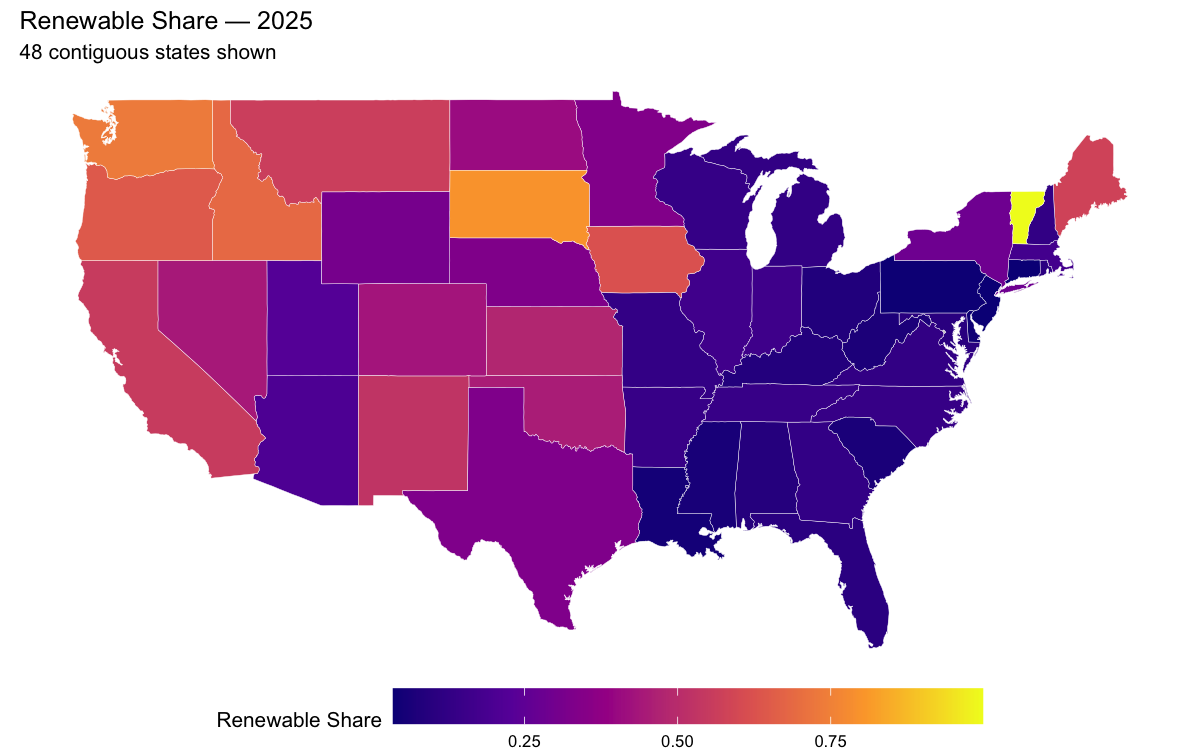

Private data-center jobs per 1,000 workers, lagged, 2025 (BLS QCEW). AK, ND, SD and WY are suppressed only in 2025 itself, so this lag uses 2024.

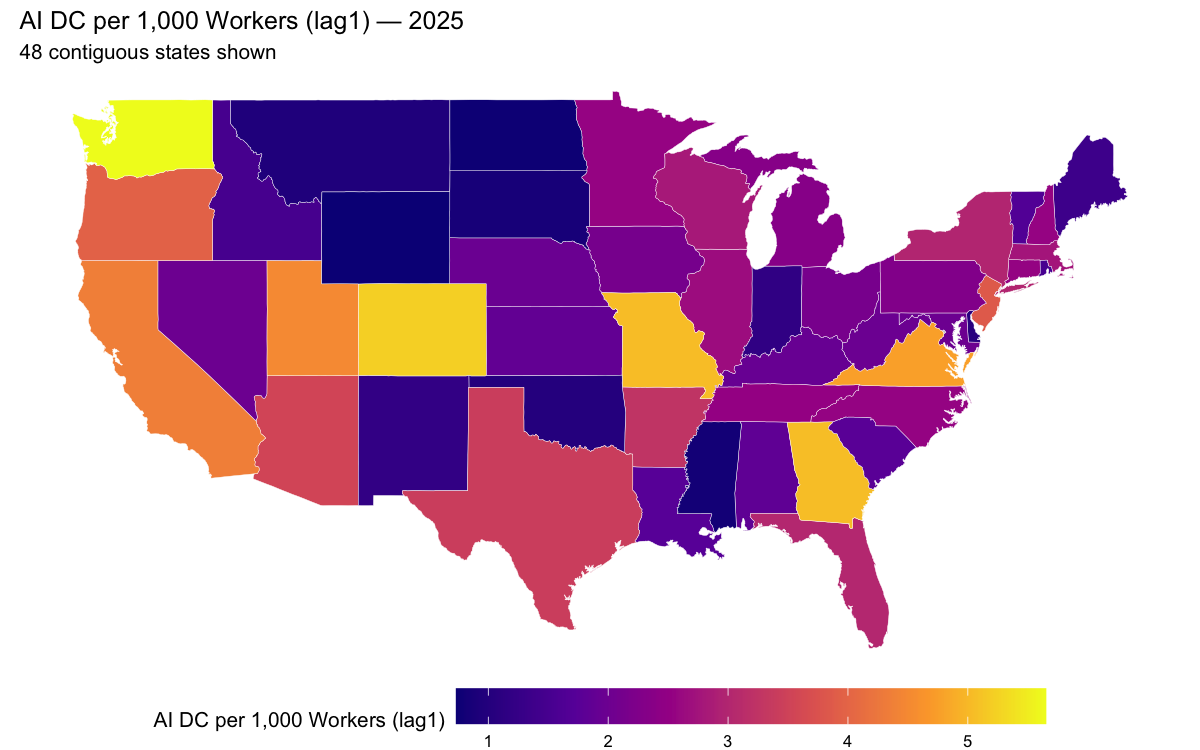

Georgia and the U.S.: private data-center jobs per 1,000 workers and renewable share.

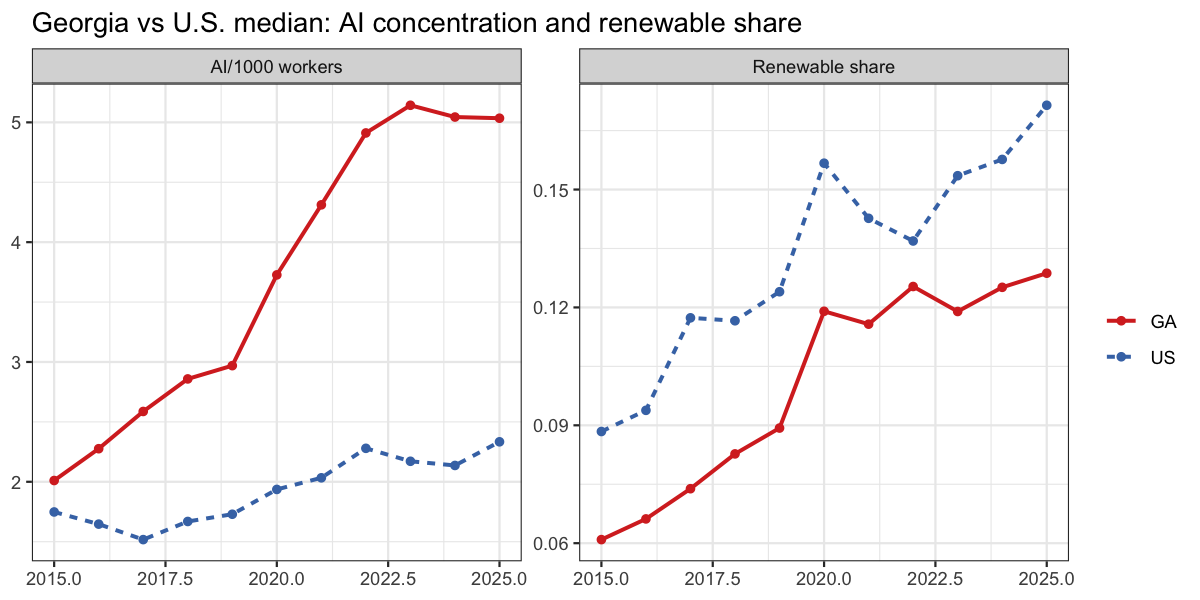

H1: AI(t-1) per one within-state SD of AI (0.5212: winsorized lagged AI after removing state and year effects), with 95% CIs. One panel per unit. Two-way FE, ctrl4, clustered by state.

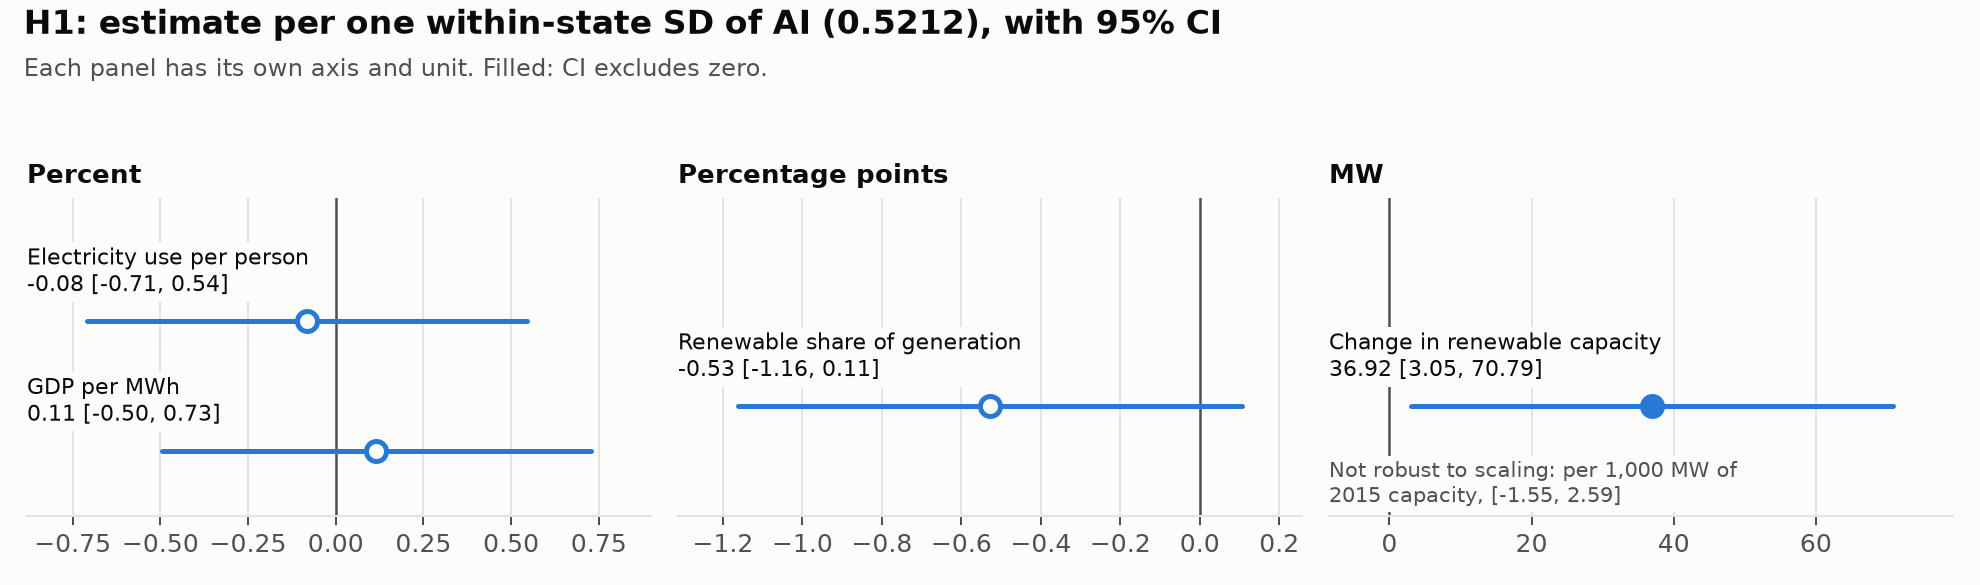

The AI coefficient across specifications. Next-year AI is significant for renew_share, while AI(t-1) isn't on the same sample.

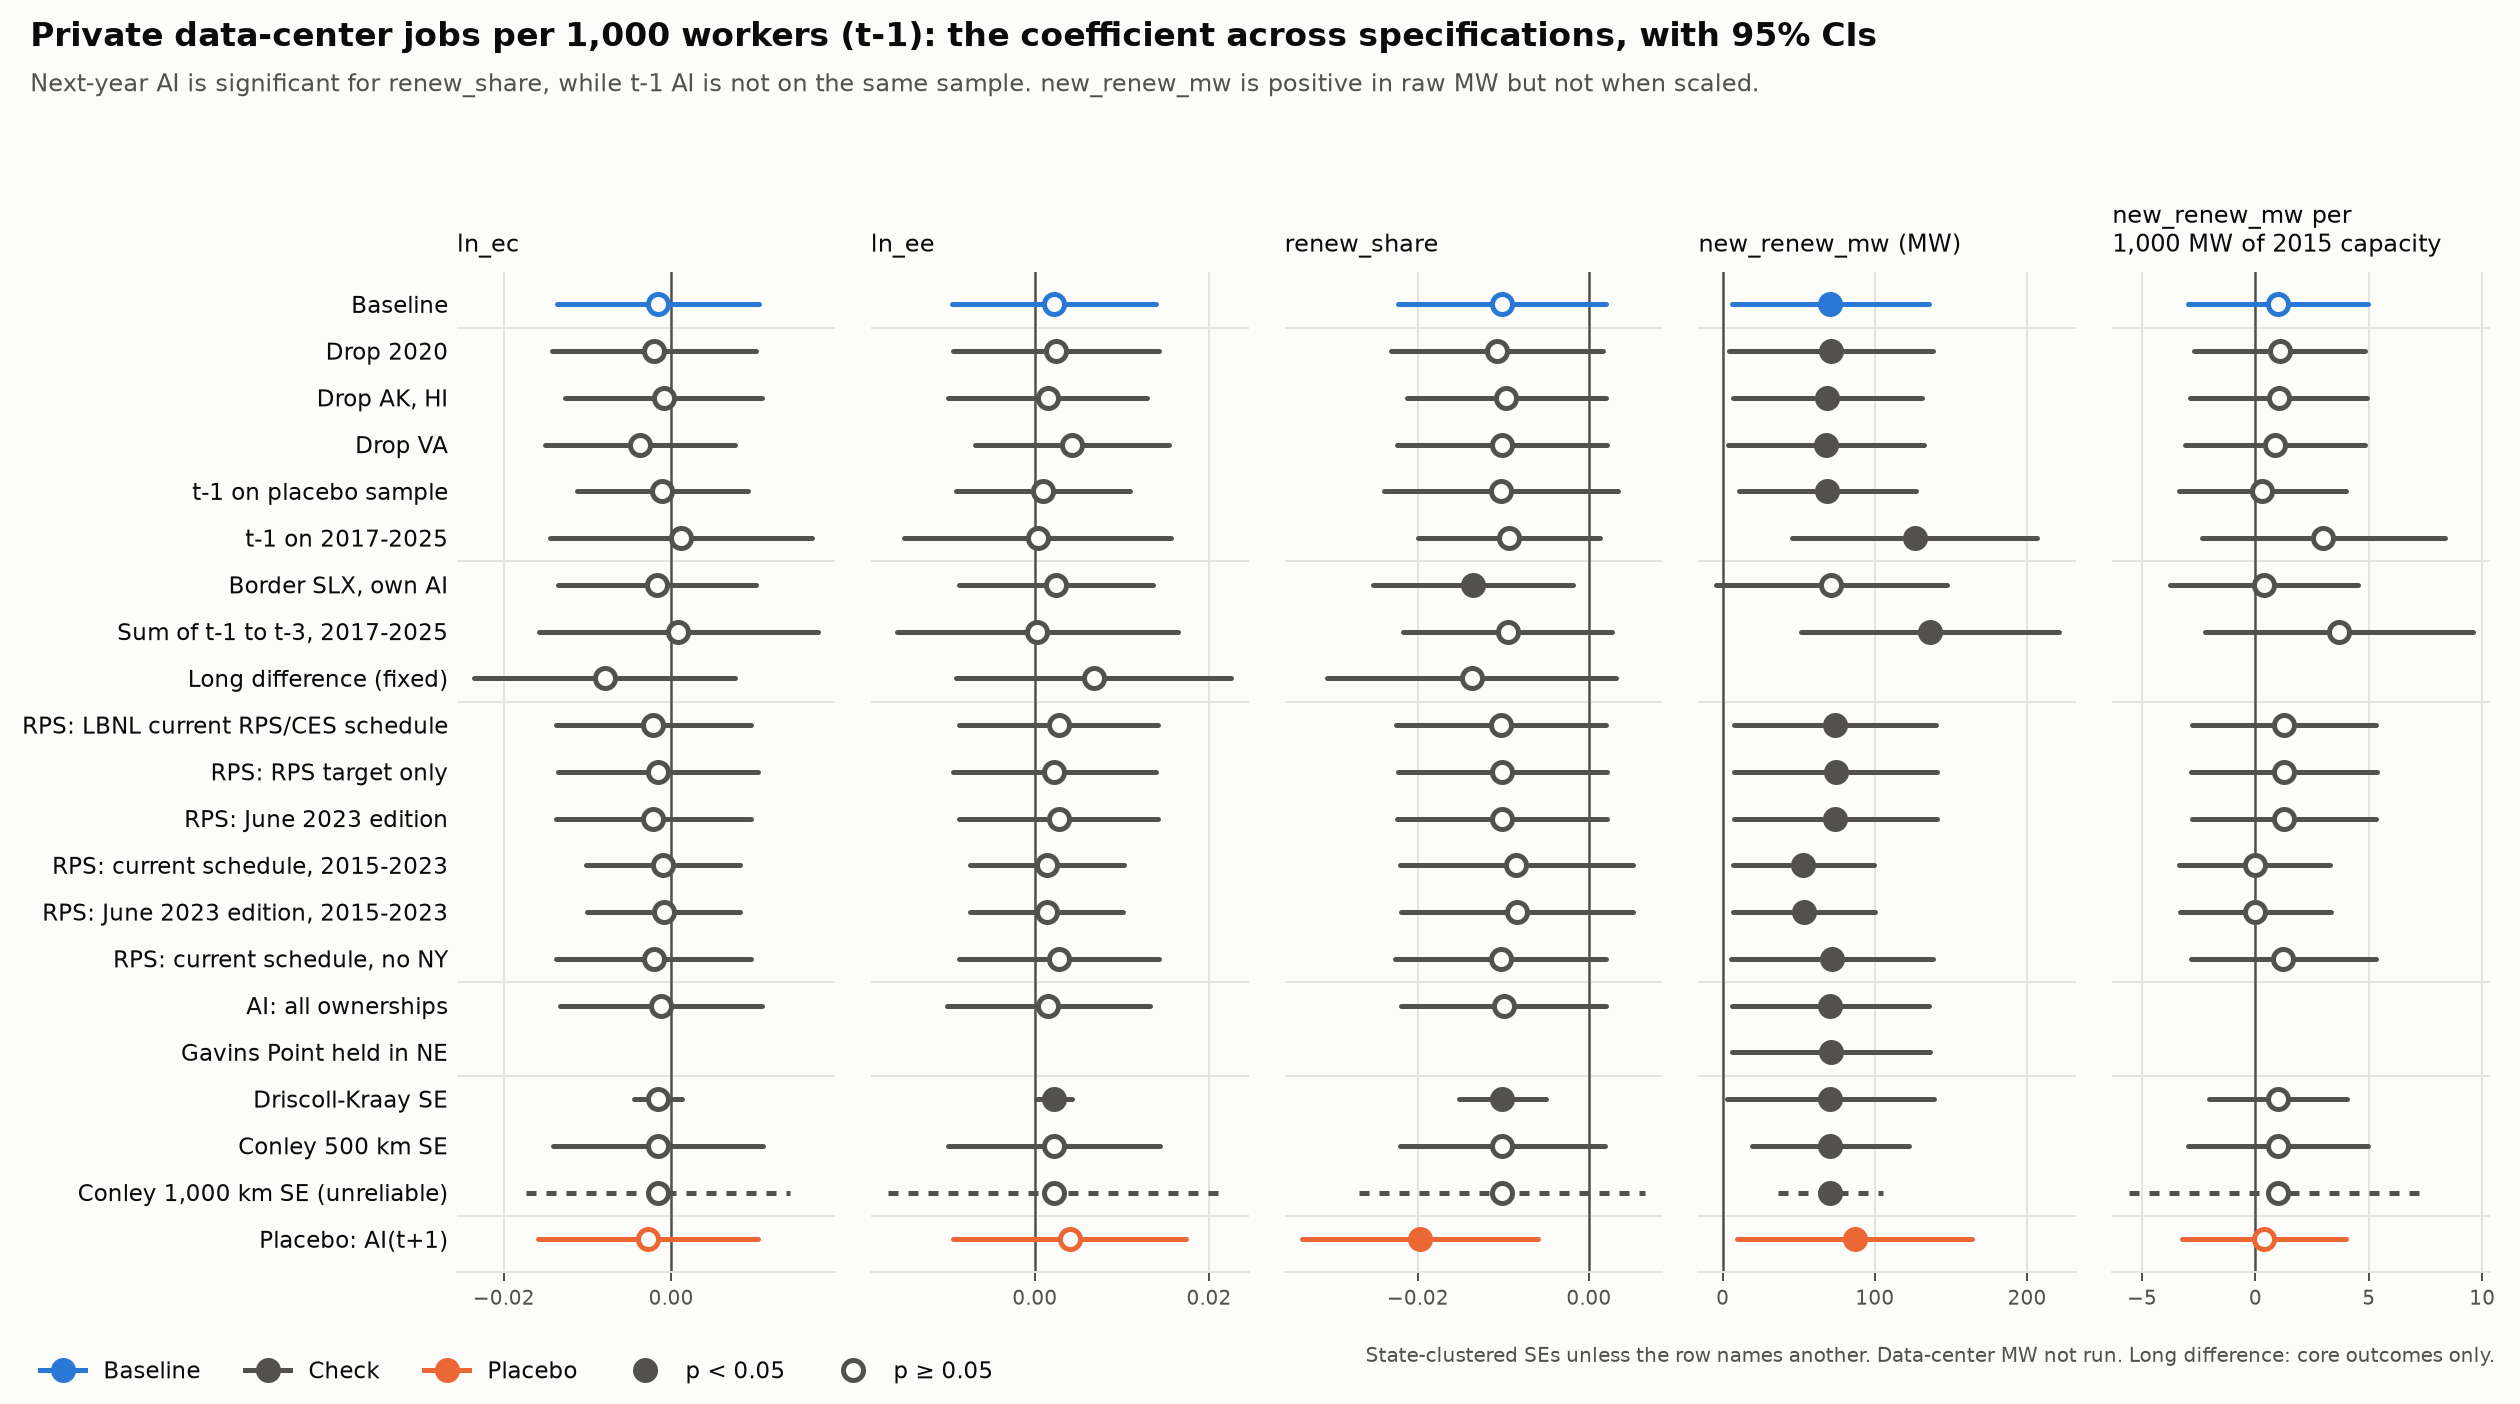

The renew_share spillover under the timing test. It isn't significant on 2015-2023, and with border weights neighbors' future AI carries the association.

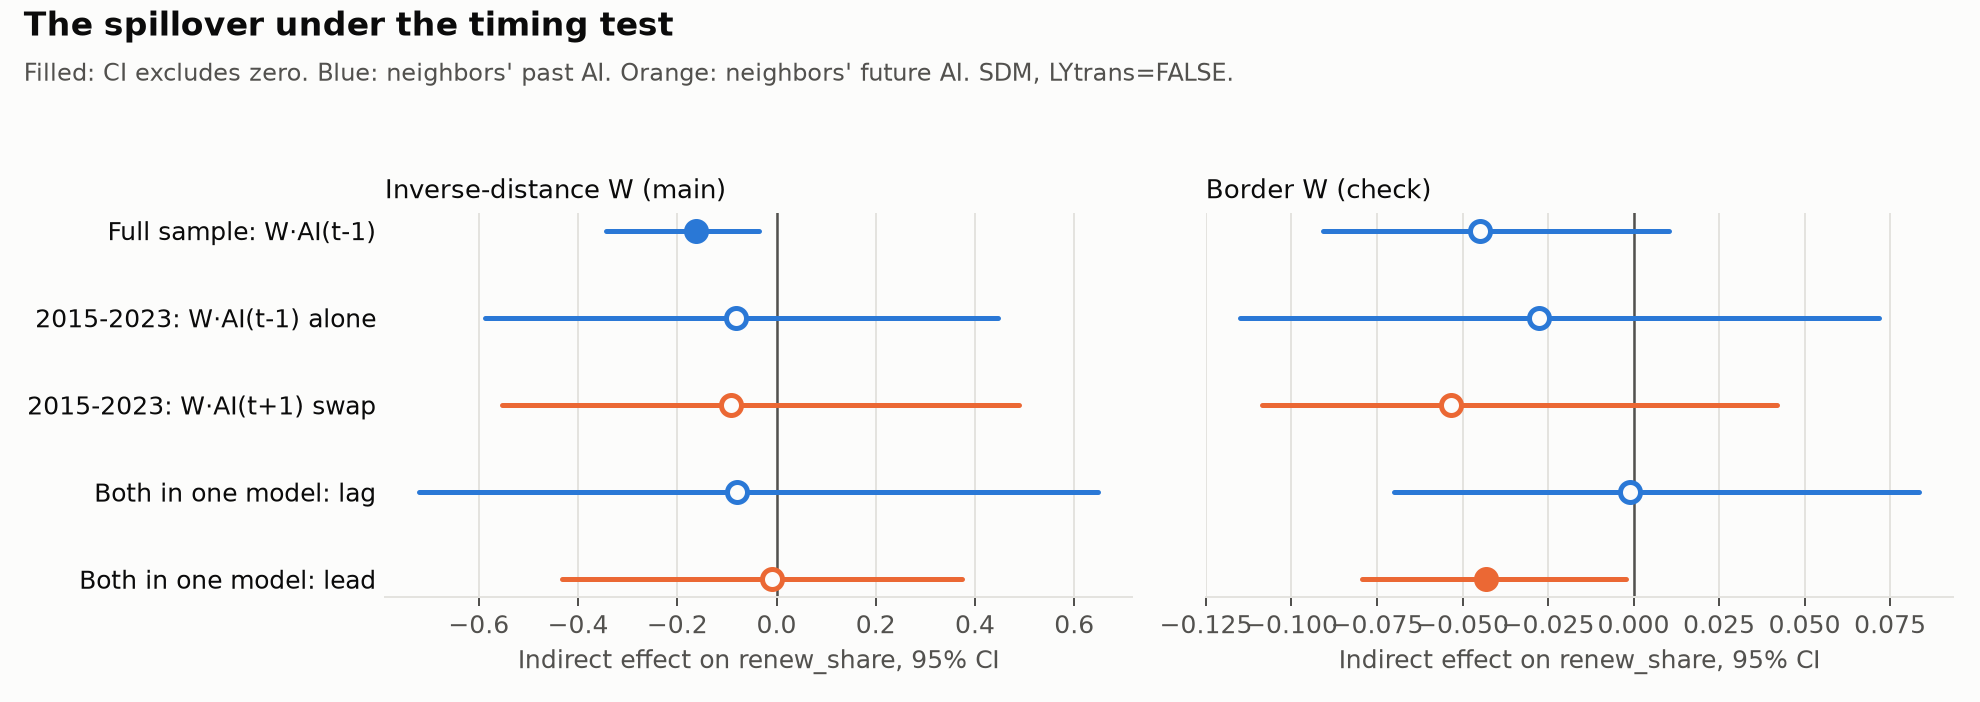

The AI coefficient from Fang's spec to ours. Data-center jobs are the more reliable extension measure.

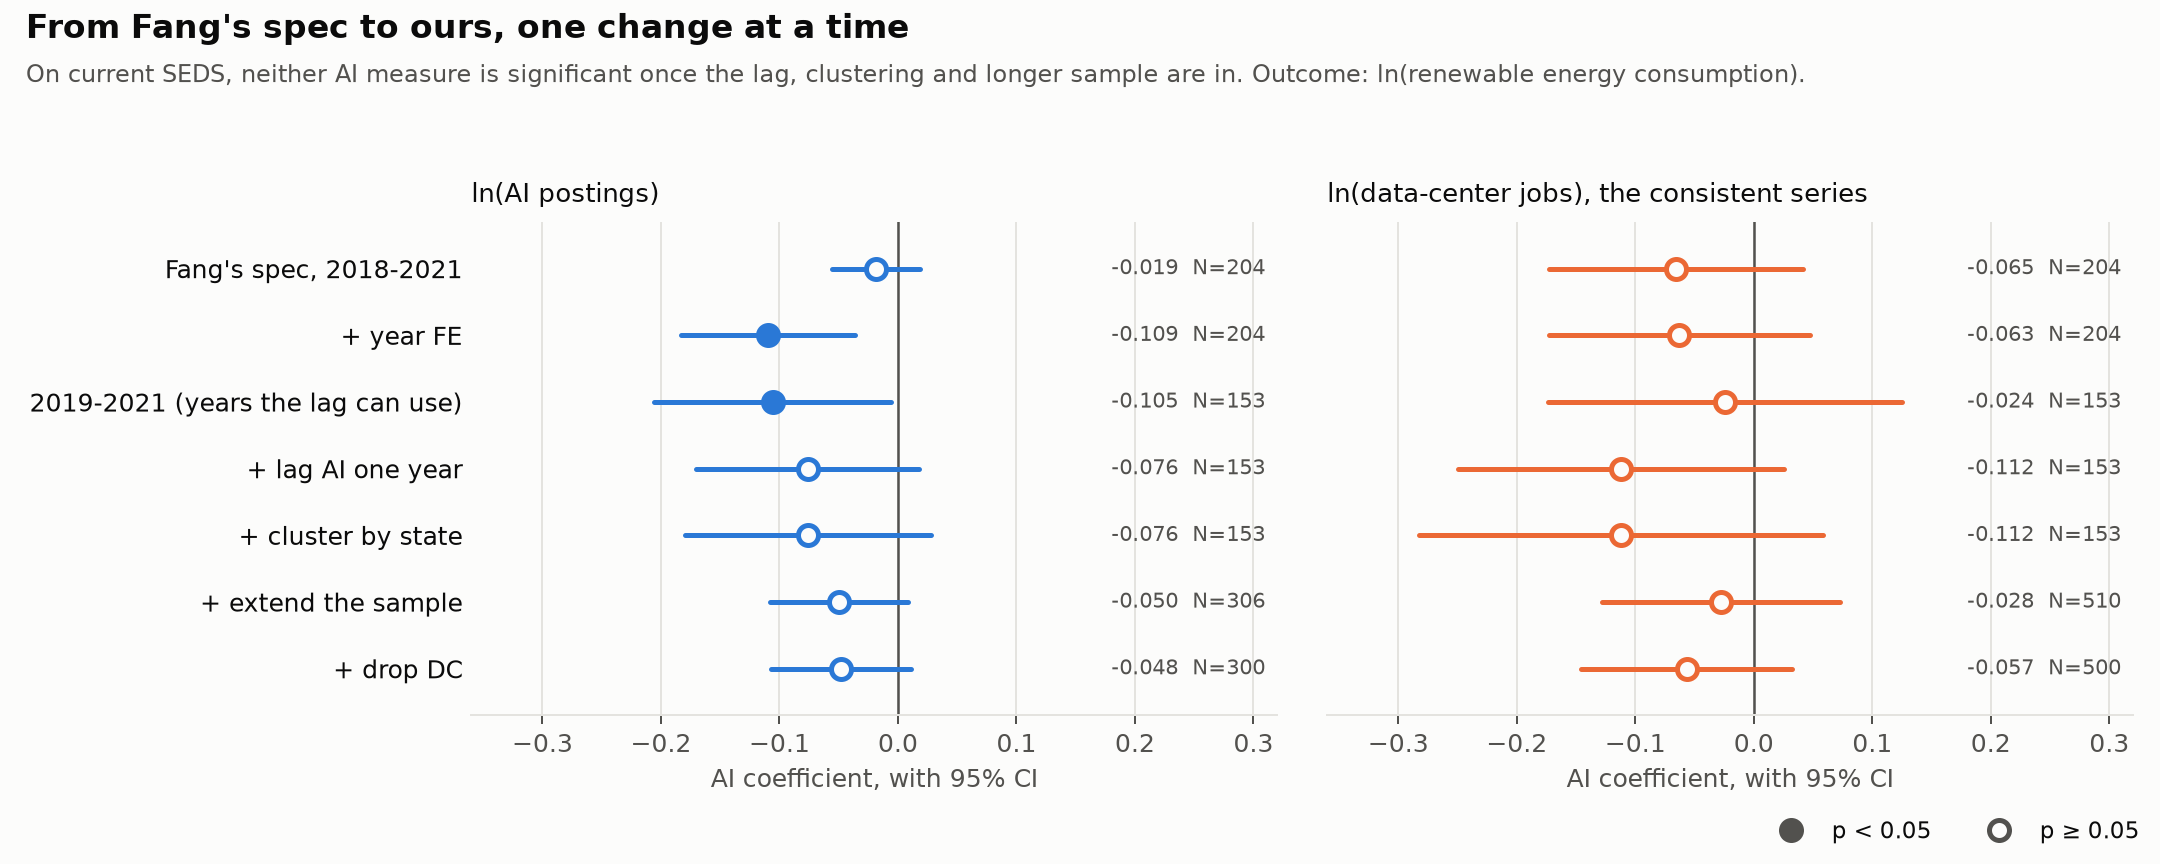

AI slope at the 25th and 75th percentiles of broadband and R&D share.

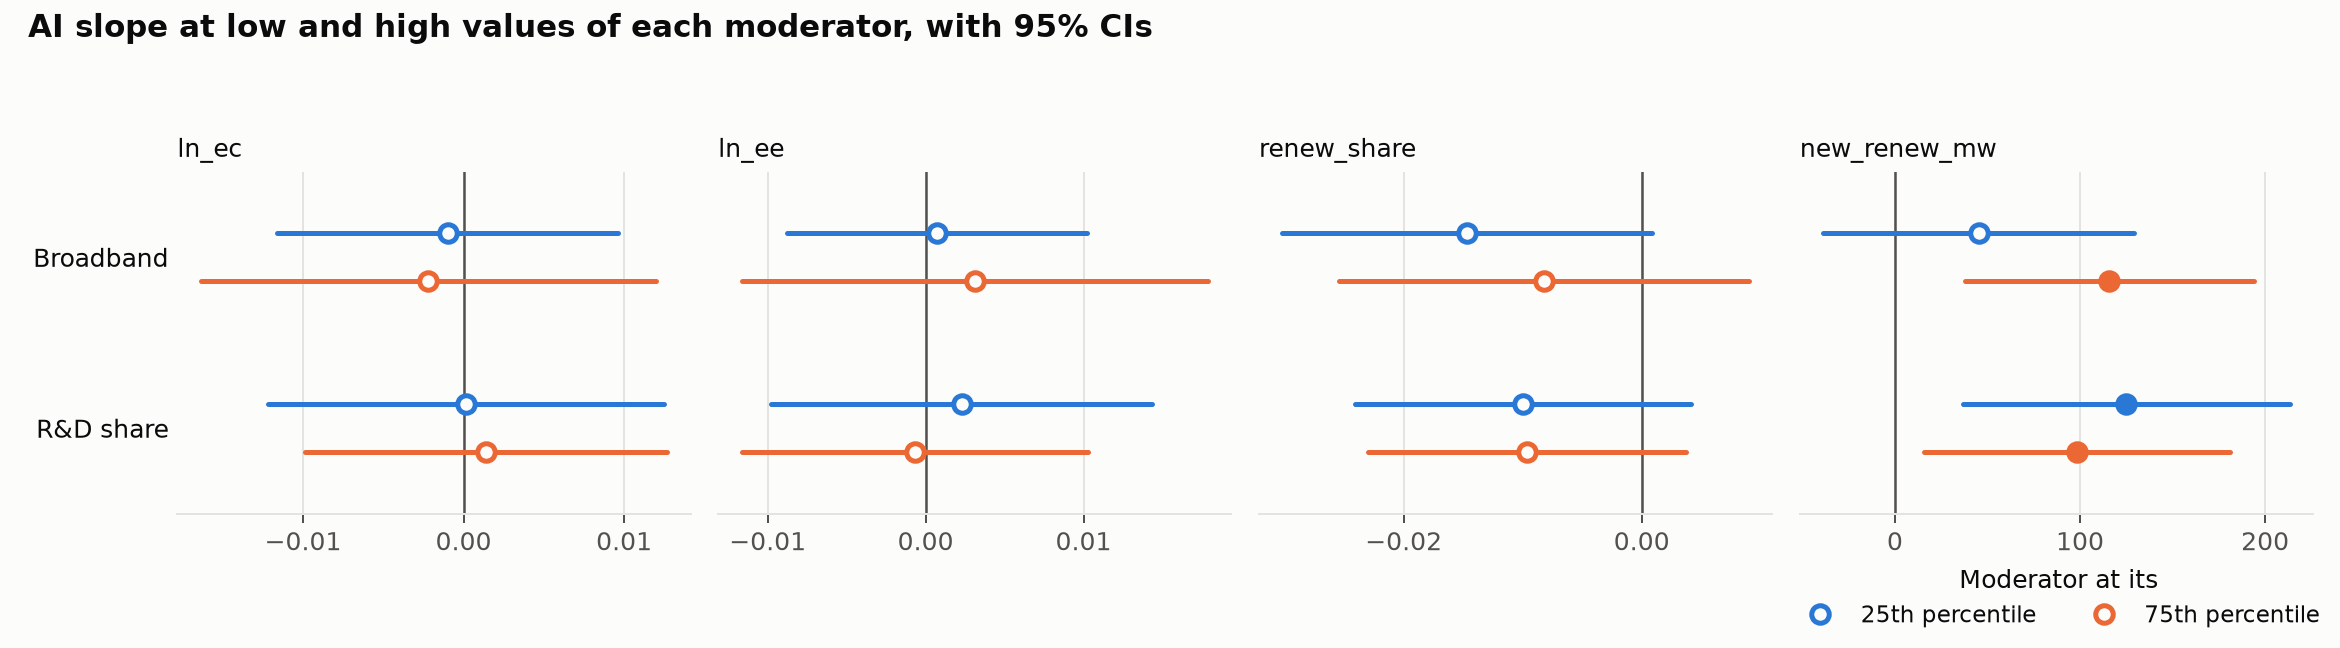

Georgia solar: learning-curve arithmetic to 2035 on IEA WEO 2025 paths (Annex A, Tables A.3a, A.3b and A.3c; pp. 417, 423 and 429). Not a forecast of ours.

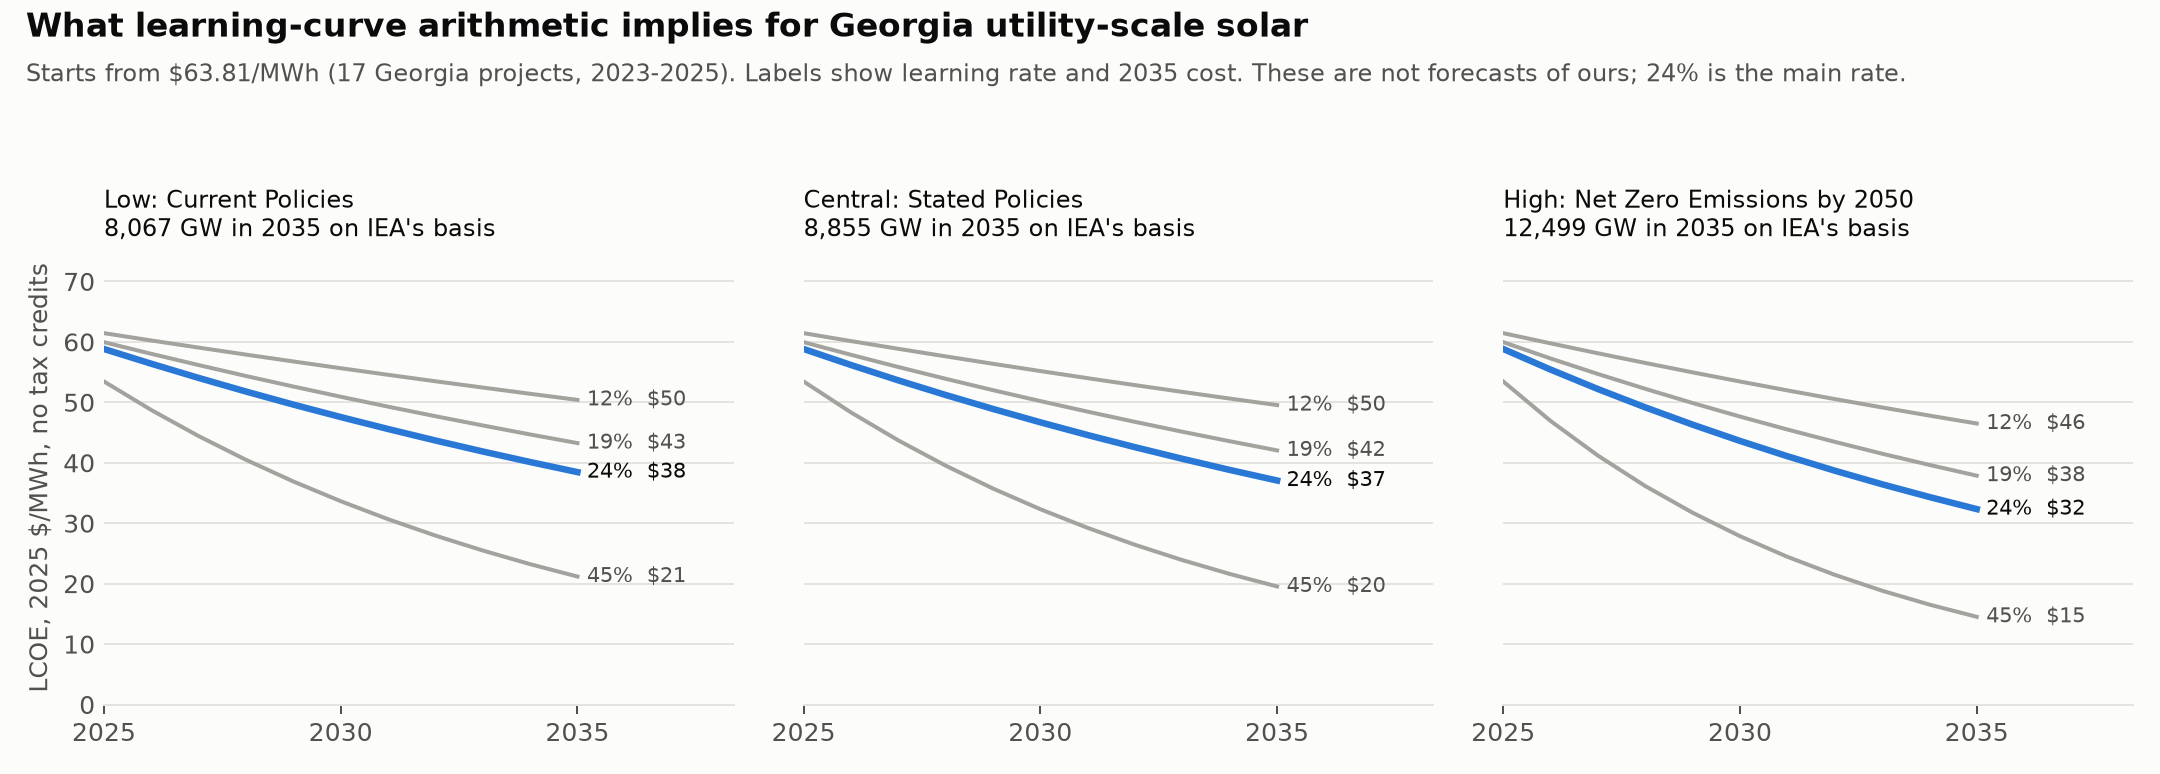

In [3]:
import re
for f, cap in re.findall(r'\*\*`(.+?)`\.\*\* (.+)', open(P + 'figures/CAPTIONS.md').read()):
    display(Markdown(cap)); display(Image(P + 'figures/' + f, width=900))

## Number check

In [4]:
n = pd.read_csv(P + 'number_check.csv'); display(n.match.value_counts()); display(n)

match
yes                         84
published; check by hand     5
Name: count, dtype: int64

,number,document,source_file,source_tag,column,in_document,match
0,550,findings.md,results/2026-11-02/h1/h1_core.csv,h1_twfe_ai518210_lag1_ctrl4_w9901_cl-state_ln_ec_50s2015_2025,N,yes,yes
1,-0.0016,findings.md,results/2026-11-02/h1/h1_core.csv,h1_twfe_ai518210_lag1_ctrl4_w9901_cl-state_ln_ec_50s2015_2025,estimate,yes,yes
2,0.795,findings.md,results/2026-11-02/h1/h1_core.csv,h1_twfe_ai518210_lag1_ctrl4_w9901_cl-state_ln_ec_50s2015_2025,pval,yes,yes
3,0.0022,findings.md,results/2026-11-02/h1/h1_core.csv,h1_twfe_ai518210_lag1_ctrl4_w9901_cl-state_ln_ee_50s2015_2025,estimate,yes,yes
4,0.707,findings.md,results/2026-11-02/h1/h1_core.csv,h1_twfe_ai518210_lag1_ctrl4_w9901_cl-state_ln_ee_50s2015_2025,pval,yes,yes
...,...,...,...,...,...,...,...
84,14.51,findings.md,results/2026-11-04/georgia_solar/projection_long.csv,ga_solar_lc_lr45_cap-high_2035,lcoe_2025usd_mwh,yes,yes
85,50.40,findings.md,results/2026-11-04/georgia_solar/projection_long.csv,ga_solar_lc_lr12_cap-low_2035,lcoe_2025usd_mwh,yes,yes
86,"4,000",findings.md,"Georgia Power 2025 IRP, Main Document, PDF p. 67",published,NaN,yes,published; check by hand
87,49.0,findings.md,results/2026-11-04/georgia_solar/national_lcoe_lbnl_tab.csv,{'year': 2022},lcoe,yes,yes
